<a href="https://colab.research.google.com/github/Nicolas-Mariano/Inteligencia-Artificial-6B/blob/main/Familia_Peixe_Nicolas_Mariano_6B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("menegidio/fishmorph-dataset")

print("Path to dataset files:", path)

100%|██████████| 844k/844k [00:00<00:00, 99.7MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/menegidio/fishmorph-dataset/versions/1


##Importações
Todas as bibliotecas necessárias

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix



##Carregamento dos Dados
Importa o arquivo CSV

In [ ]:
caminho = '/root/.cache/kagglehub/datasets/menegidio/fishmorph-dataset/versions/1/FISHMORPH_Family_Dataset.csv'
df = pd.read_csv(caminho)

display(df.head())

,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Family
0,130.0,4.579113,0.622642,0.375019,0.622642,0.868659,0.484981,0.273585,0.144108,3.348991,Cyprinidae
1,11.5,2.796068,0.650700,0.353780,0.509800,0.411157,0.722461,0.330169,0.221095,2.525592,Cichlidae
2,6.6,4.564329,0.518187,0.312002,0.203985,0.413221,0.591495,0.105517,0.188193,2.104580,Cyprinidae
3,10.9,4.390422,0.548247,0.244804,0.168959,0.324728,0.642991,0.097450,0.193049,1.787062,Cyprinidae
4,18.9,4.410271,0.542353,0.292058,0.183790,0.398567,0.685672,0.087643,0.170648,2.968906,Cyprinidae


##Análise Básica
Verifica os tipos de dados e a existência de valores nulos.

In [ ]:
print("--- Tipos de Dados ---")
df.info()

print("\n--- Valores Nulos ---")
print(df.isnull().sum())

--- Tipos de Dados ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8342 entries, 0 to 8341
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   MBl     8342 non-null   float64
 1   BEl     8342 non-null   float64
 2   VEp     8342 non-null   float64
 3   REs     8342 non-null   float64
 4   OGp     8342 non-null   float64
 5   RMl     8342 non-null   float64
 6   BLs     8342 non-null   float64
 7   PFv     8342 non-null   float64
 8   PFs     8342 non-null   float64
 9   CPt     8342 non-null   float64
 10  Family  8342 non-null   object 
dtypes: float64(10), object(1)
memory usage: 717.0+ KB

--- Valores Nulos ---
MBl       0
BEl       0
VEp       0
REs       0
OGp       0
RMl       0
BLs       0
PFv       0
PFs       0
CPt       0
Family    0
dtype: int64


##Visualização das Categorias
Gera o gráfico de distribuição da coluna alvo (Family).

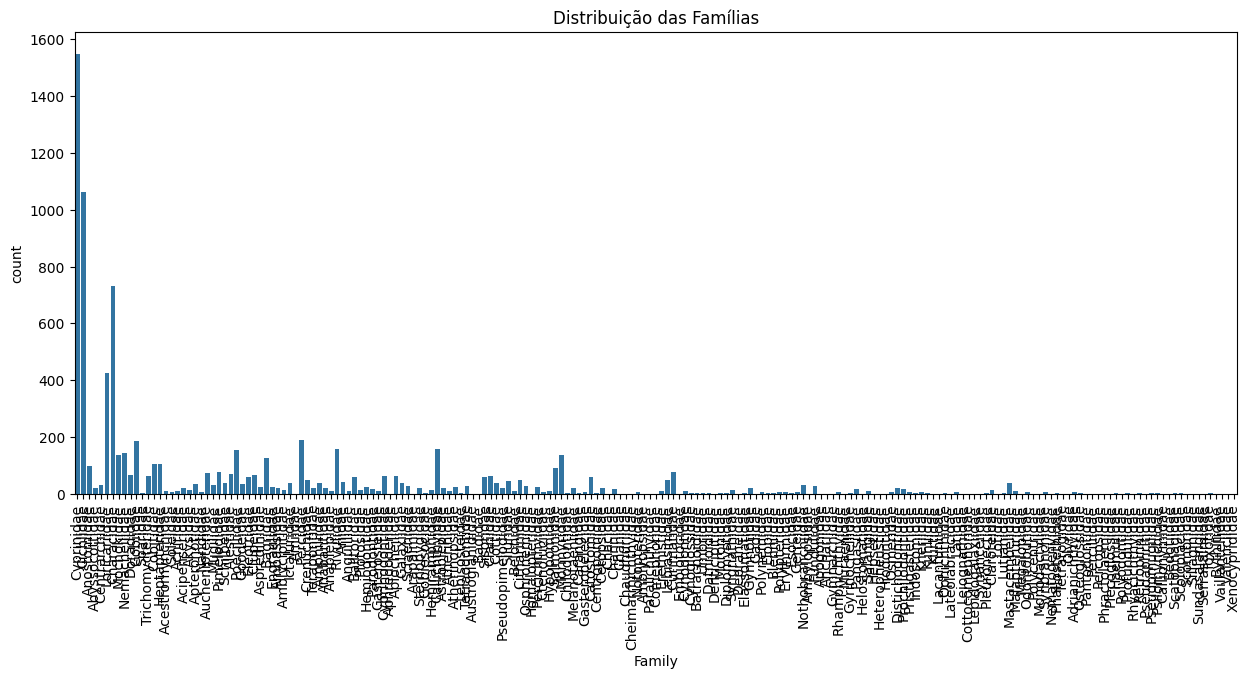

In [ ]:
plt.figure(figsize=(15, 6))
sns.countplot(data=df, x='Family')

plt.title('Distribuição das Famílias')
plt.xticks(rotation=90)
plt.show()

In [ ]:
contagem = df['Family'].value_counts()
print("Quantidade de Peixes em Cada Família")
print(contagem.to_string())

menor_quantidade = contagem.min()
print(f"\nMenor Quantidade de Peixes em Uma Família: {menor_quantidade} Peixes")

#

--- Quantidade de Peixes em Cada Família ---
Family
Cyprinidae             1545
Cichlidae              1060
Characidae              732
Loricariidae            427
Percidae                190
Gobiidae                187
Callichthyidae          159
Rivulidae               158
Poeciliidae             154
Nemacheilidae           145
Mormyridae              138
Mochokidae              137
Bagridae                129
Cobitidae               108
Heptapteridae           106
Anostomidae              99
Salmonidae               92
Pimelodidae              79
Curimatidae              79
Auchenipteridae          75
Alestidae                73
Clupeidae                69
Doradidae                68
Trichomycteridae         65
Cyprinodontidae          64
Clariidae                63
Aplocheilidae            63
Eleotridae               62
Catostomidae             62
Balitoridae              61
Sisoridae                60
Crenuchidae              52
Lebiasinidae             50
Citharinidae            

##Tratamento de Classes Raras

In [ ]:
# Filtra as famílias que possuem 2 ou mais registros
contagem = df['Family'].value_counts()
familias_validas = contagem[contagem >= 2].index
df_filtrado = df[df['Family'].isin(familias_validas)]

print(f"Linhas antes do filtro: {df.shape[0]}")
print(f"Linhas após remover classes únicas: {df_filtrado.shape[0]}")

Linhas antes do filtro: 8342
Linhas após remover classes únicas: 8307


##Divisão Treino e Teste

In [ ]:
# Separa os dados usando o dataset já limpo
X = df_filtrado.drop('Family', axis=1)
y = df_filtrado['Family']

# Agora o stratify vai funcionar perfeitamente
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Amostras de Treino: {X_train.shape[0]}")
print(f"Amostras de Teste: {X_test.shape[0]}")

Amostras de Treino: 6645
Amostras de Teste: 1662


##Padronização dos Dados
Modelos baseados em distância (como o SVM) exigem que todas as colunas numéricas estejam na mesma escala. O StandardScaler faz exatamente isso.

In [37]:
# Instancia o padronizador
scaler = StandardScaler()

# ATENÇÃO: No treino a gente 'aprende' o padrão e transforma (fit_transform)
X_train_scaled = scaler.fit_transform(X_train)

# No teste a gente APENAS transforma (transform), para não vazar dados do teste pro treino
X_test_scaled = scaler.transform(X_test)

print("Dados padronizados")

Dados padronizados


##Amostragem para o Grid Search
Pegamos uma amostra menor de 30%.

In [38]:
# 1. Filtro de segurança: garante que a amostra de treino não tenha classes com apenas 1 peixe
contagem_treino = y_train.value_counts()
familias_validas_treino = contagem_treino[contagem_treino >= 2].index
mascara = y_train.isin(familias_validas_treino)

# 2. Aplica a máscara nos dados de treino
X_train_seguro = X_train_scaled[mascara]
y_train_seguro = y_train[mascara]

# 3. Extrai apenas 30% da base para fazer a busca de parâmetros
X_amostra, _, y_amostra, _ = train_test_split(
    X_train_seguro, y_train_seguro, train_size=0.3, random_state=42, stratify=y_train_seguro
)

print(f"Tamanho da amostra para o GridSearch: {X_amostra.shape[0]} linhas")

Tamanho da amostra para o GridSearch: 1993 linhas


##Grid Search (Testando os Parâmetros)
Aqui nós cumprimos a exigência da sua prova: testar 4 valores diferentes para kernel, C e gamma.



In [ ]:
# 1. Dicionário com os 4 valores de cada hiperparâmetro exigido
parametros = {
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'], # Formatos da fronteira de decisão
    'C': [0.1, 1, 10, 100],                         # Penalidade por erros
    'gamma': ['scale', 'auto', 0.1, 0.01]           # Raio de influência de cada amostra
}

# 2. Configura o GridSearch (cv=5 significa Cross-Validation com 5 divisões)
# verbose=1 vai mostrar o progresso na tela, e n_jobs=-1 usa todos os núcleos do processador
grid = GridSearchCV(SVC(), parametros, cv=5, n_jobs=-1, verbose=1)

print("Iniciando a busca pelos melhores parâmetros...\n")
grid.fit(X_amostra, y_amostra)

print("\nMelhores Parâmetros Encontrados")
print(grid.best_params_)

Iniciando a busca pelos melhores parâmetros...

Fitting 5 folds for each of 64 candidates, totalling 320 fits


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(



Melhores Parâmetros Encontrados
{'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}


##Tabela de Resultados (Modelo, Parâmetros e Acurácia)


In [40]:
modelo_final = SVC(**grid.best_params_)

modelo_final.fit(X_train_scaled, y_train)

previsoes = modelo_final.predict(X_test_scaled)
acuracia = accuracy_score(y_test, previsoes)

dados_tabela = {
    'Métrica / Parâmetro': ['Modelo', 'Parâmetro: Kernel', 'Parâmetro: C', 'Parâmetro: Gamma', 'Acurácia Final'],
    'Valor Escolhido': ['Support Vector Machine (SVM)', grid.best_params_['kernel'], grid.best_params_['C'], grid.best_params_['gamma'], acuracia]
}

tabela_resultados = pd.DataFrame(dados_tabela)

print("RESULTADOS ")
display(tabela_resultados)


RESULTADOS 


,Métrica / Parâmetro,Valor Escolhido
0,Modelo,Support Vector Machine (SVM)
1,Parâmetro: Kernel,rbf
2,Parâmetro: C,10
3,Parâmetro: Gamma,scale
4,Acurácia Final,0.669675


##Matriz de Confusão

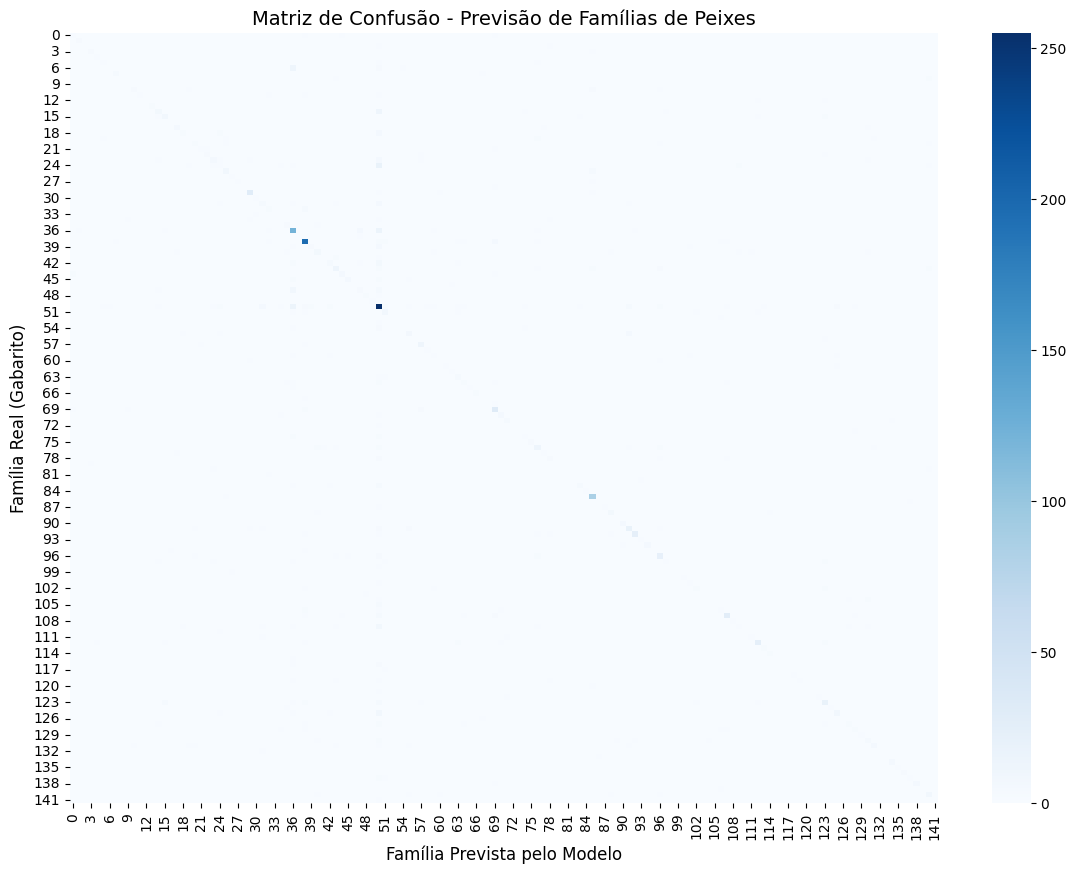

In [35]:
matriz = confusion_matrix(y_test, previsoes)

plt.figure(figsize=(14, 10))

sns.heatmap(matriz, annot=False, cmap='Blues')

plt.title('Matriz de Confusão - Previsão de Famílias de Peixes', fontsize=14)
plt.xlabel('Família Prevista pelo Modelo', fontsize=12)
plt.ylabel('Família Real (Gabarito)', fontsize=12)

plt.show()